 ## Setup & Load 

In [7]:
# imports
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, pearsonr, probplot

sns.set_theme()
pd.set_option("display.max_colwidth", 200)

# path to dataset (edit if needed)
PATH = "amz_uk_price_prediction_dataset.csv"

# load
df = pd.read_csv(PATH)

# unify column names
df.columns = df.columns.str.lower().str.replace(r"\s+", "_", regex=True)

# optional renames (works only if present)
df = df.rename(columns={
    "product_category":"category",
    "best_seller":"bestseller",
    "bestseller_status":"bestseller",
    "star_rating":"stars",
    "rating":"stars"
})

# quick check
df.head()



,uid,asin,title,stars,reviews,price,isbestseller,boughtinlastmonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big vibrant sound Wi-Fi and Bluetooth smart speaker with Alexa | Charcoal",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth Speaker with 15-Hour Playtime, 66-Foot Bluetooth Range, Wireless Speaker with Enhanced Bass, Noise-Cancelling Microphone, for Outdoor, Travel, Home",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big vibrant sound Wi-Fi and Bluetooth smart speaker with Alexa | Deep Sea Blue",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 release) | Bigger vibrant sound Wi-Fi and Bluetooth smart speaker and Alexa | Cloud Blue",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-Fi and Bluetooth smart speaker with Alexa | Charcoal,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [8]:
# basic cleaning
# price: keep digits/decimals, cast to float
df["price"] = (
    df["price"]
    .astype(str)
    .str.replace(r"[^0-9.\-]", "", regex=True)
    .replace({"": np.nan, ".": np.nan})
    .astype(float)
)

# stars numeric
if "stars" in df:
    df["stars"] = pd.to_numeric(df["stars"], errors="coerce")

# bestseller to string (yes/no)
if "bestseller" in df:
    df["bestseller"] = df["bestseller"].astype(str).str.strip().str.lower()

# drop obvious nulls
df = df.dropna(subset=["category","price"])


## Part 1 — Best-Seller Trends Across Categories

In [15]:
# Crosstab counts and row % (prevalence within category)
ct = pd.crosstab(df["category"], df["isbestseller"])
ct_prop = ct.div(ct.sum(1), 0).sort_values(by=True, ascending=False)

ct.head(), ct_prop.head()





(isbestseller                   False  True 
 category                                   
 3D Printers                      247      1
 3D Printing & Scanning          4065      2
 Abrasive & Finishing Products    245      5
 Action Cameras                  1696      1
 Adapters                         251      3,
 isbestseller                       False     True 
 category                                          
 Grocery                         0.941865  0.058135
 Smart Home Security & Lighting  0.942308  0.057692
 Health & Personal Care          0.942314  0.057686
 Mobile Phone Accessories        0.957529  0.042471
 Power & Hand Tools              0.964661  0.035339)

#### Chi-Square & Cramér’s V

In [18]:
# chi-square test
chi2, p, dof, _ = chi2_contingency(ct)
n = ct.to_numpy().sum()
k = min(ct.shape)

# Cramér's V
cramers_v = np.sqrt(chi2 / (n * (k - 1)))
print(f"chi2={chi2:.2f}, dof={dof}, p={p:.4g}, V={cramers_v:.3f}")


chi2=36540.20, dof=295, p=0, V=0.122


#### Stacked Bar (Top 20 categories)

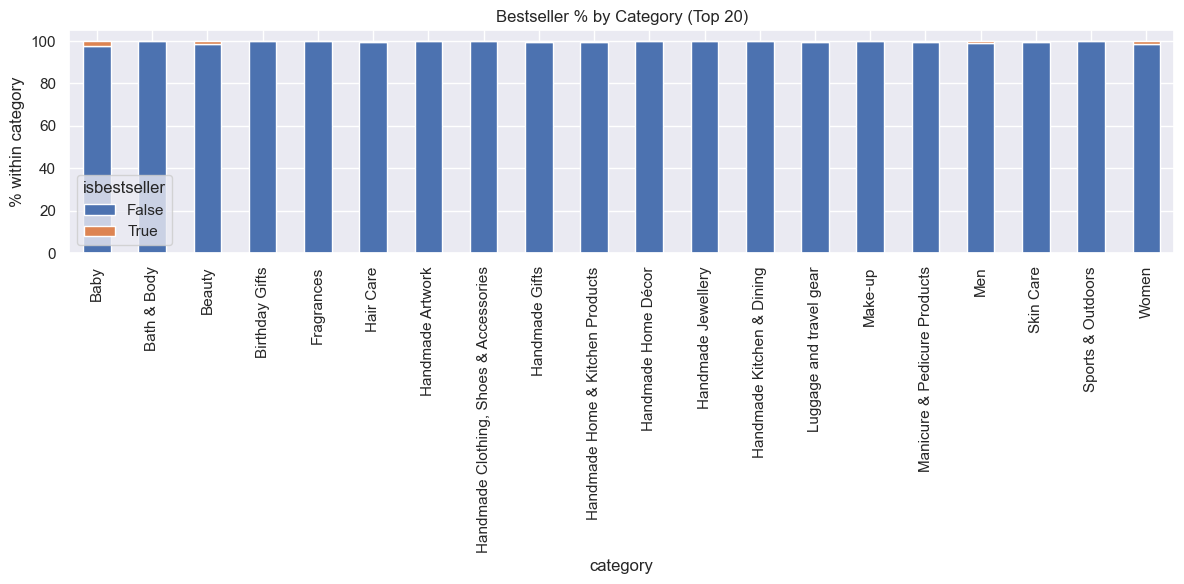

In [19]:
# top 20 categories
top20 = ct.sum(1).nlargest(20).index
ct20 = pd.crosstab(df.loc[df["category"].isin(top20), "category"],
                   df.loc[df["category"].isin(top20), "isbestseller"])

(ct20.div(ct20.sum(1),0)*100).plot(kind="bar", stacked=True, figsize=(12,6))
plt.ylabel("% within category")
plt.title("Bestseller % by Category (Top 20)")
plt.legend(title="isbestseller")
plt.tight_layout()
plt.show()


# Part 2 — Exploring Product Prices and Ratings Across Categories and Brands

#### 2.0 Remove Price Outliers (IQR method)

In [20]:
# IQR rule for price
Q1, Q3 = df["price"].quantile([0.25, 0.75])
IQR = Q3 - Q1
low, high = Q1 - 1.5*IQR, Q3 + 1.5*IQR

df_no = df[(df["price"] >= low) & (df["price"] <= high)].copy()
print(df.shape, "->", df_no.shape)  # before vs after


(2443651, 9) -> (2115963, 9)


#### 2.1 Violin Plot: Price Distribution by Category (Top 20 by Count)

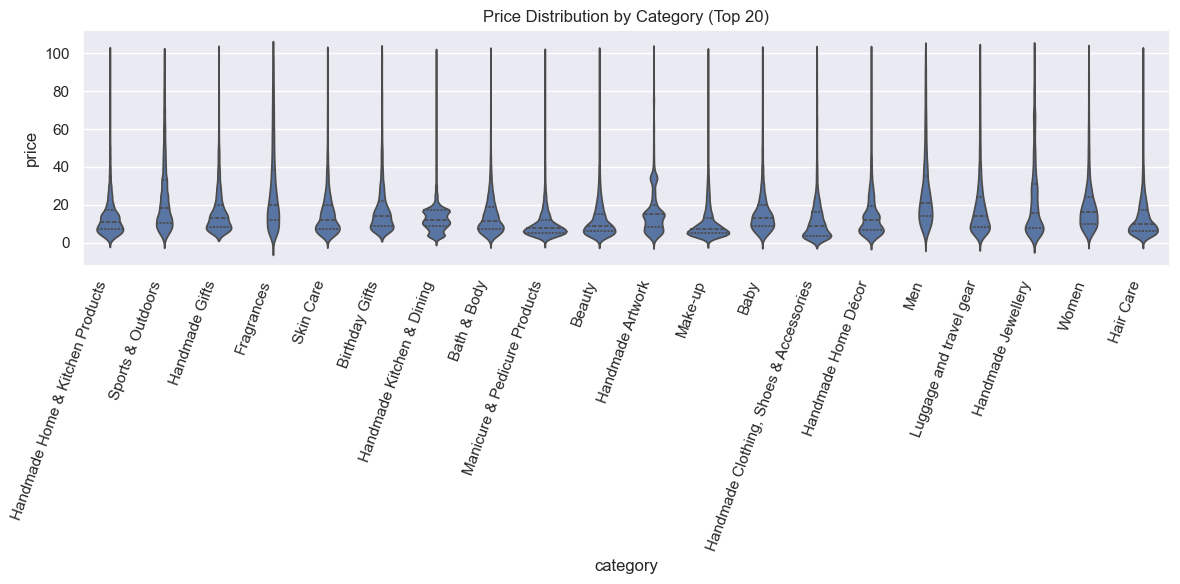

category
Men                        20.99
Fragrances                 20.00
Sports & Outdoors          18.32
Women                      15.99
Handmade Jewellery         15.60
Handmade Artwork           14.99
Birthday Gifts             13.99
Luggage and travel gear    13.99
Baby                       12.99
Handmade Gifts             12.99
Name: price, dtype: float64

In [22]:
# top 20 categories by product count
top20 = df_no["category"].value_counts().head(20).index
d20 = df_no[df_no["category"].isin(top20)]

plt.figure(figsize=(12,6))
sns.violinplot(data=d20, x="category", y="price", inner="quart")
plt.xticks(rotation=70, ha="right")
plt.title("Price Distribution by Category (Top 20)")
plt.tight_layout()
plt.show()

# median price per category
med_price = d20.groupby("category")["price"].median().sort_values(ascending=False)
med_price.head(10)


#### 2.2 Bar Chart: Average Price by Category (Top 10)

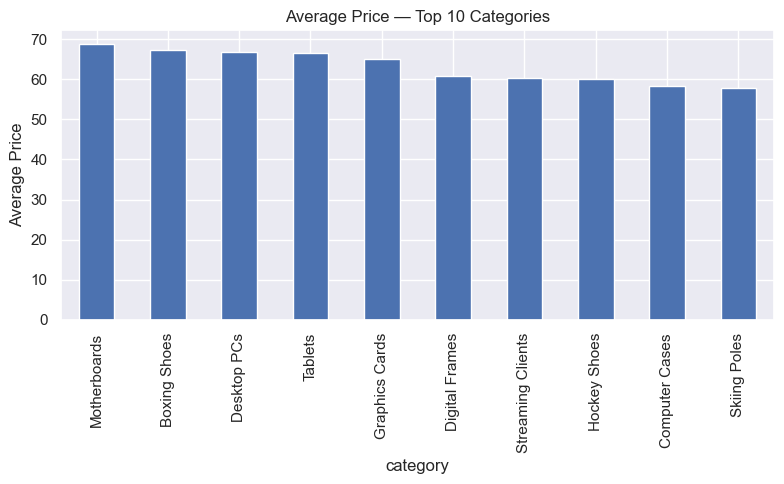

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

In [23]:
avg_price = (
    df_no.groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(8,5))
avg_price.plot(kind="bar")
plt.ylabel("Average Price")
plt.title("Average Price — Top 10 Categories")
plt.tight_layout()
plt.show()

avg_price


#### 2.3 Box Plot: Ratings by Category (Top 10)

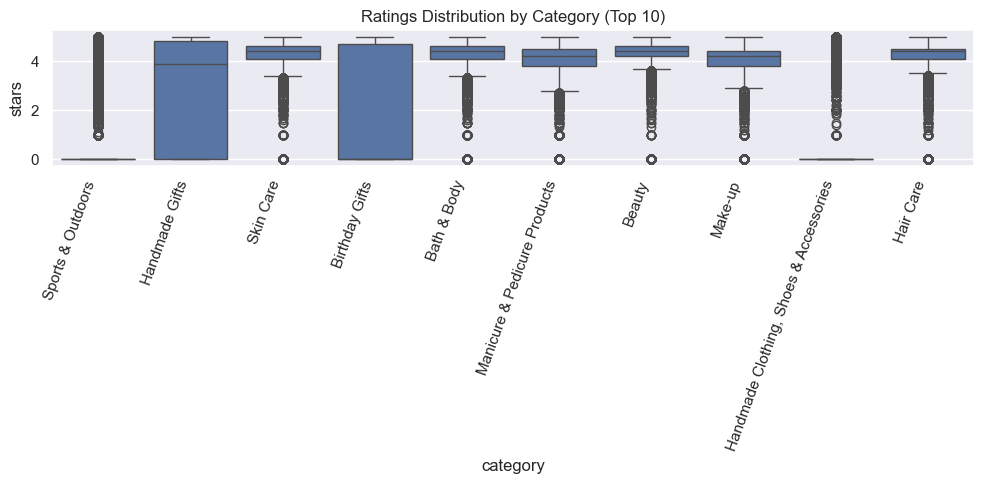

category
Bath & Body    4.4
Beauty         4.4
Hair Care      4.4
Skin Care      4.4
Make-up        4.2
Name: stars, dtype: float64

In [24]:
# drop rows without star ratings
d_stars = df_no.dropna(subset=["stars"]).copy()

# top 10 categories by count
top10_rate = d_stars["category"].value_counts().head(10).index
d10 = d_stars[d_stars["category"].isin(top10_rate)]

plt.figure(figsize=(10,5))
sns.boxplot(data=d10, x="category", y="stars")
plt.xticks(rotation=70, ha="right")
plt.title("Ratings Distribution by Category (Top 10)")
plt.tight_layout()
plt.show()

# median stars per category
d10.groupby("category")["stars"].median().sort_values(ascending=False).head()


# Part 3 — Investigating the Interplay Between Product Prices and Ratings

#### 3.1 Correlation Between Price and Stars

In [25]:
# drop rows with missing values
df_corr = df_no.dropna(subset=["price", "stars"])

# correlation coefficient
corr = df_corr["price"].corr(df_corr["stars"])
print(f"Correlation between price and stars: {corr:.3f}")


Correlation between price and stars: -0.078


#### 3.2 Scatter Plot: Price vs Stars

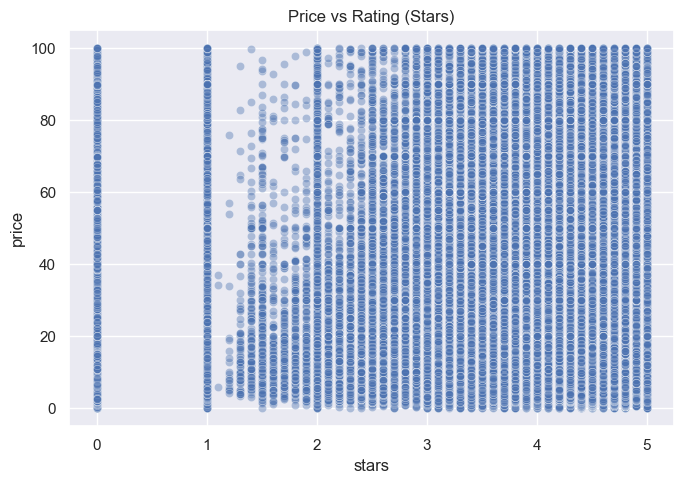

In [26]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=df_corr, x="stars", y="price", alpha=0.4)
plt.title("Price vs Rating (Stars)")
plt.tight_layout()
plt.show()


#### 3.3 Correlation Heatmap (all numeric columns)

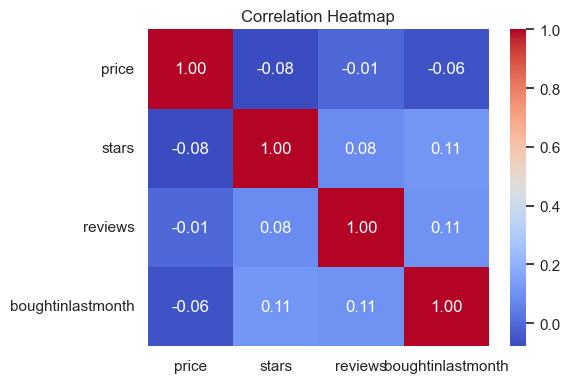

In [27]:
plt.figure(figsize=(6,4))
sns.heatmap(df_corr[["price","stars","reviews","boughtinlastmonth"]].corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


#### 3.4 QQ Plot: Check if Price is Normally Distributed

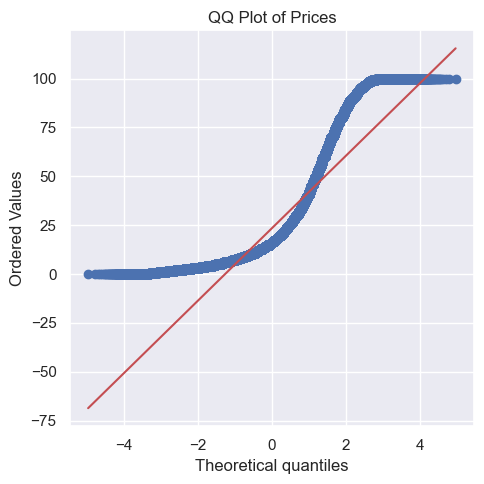

In [29]:
import scipy.stats as stats

plt.figure(figsize=(5,5))
stats.probplot(df_corr["price"], dist="norm", plot=plt)
plt.title("QQ Plot of Prices")
plt.tight_layout()
plt.show()



# Detailed Business Insights

## 1.Best-Seller Trends by Category

The Chi-Square test confirms that bestseller status is not independent of product category (p ≈ 0).

However, Cramér’s V = 0.12 suggests the relationship is weak, meaning category alone only explains a small share of bestseller variation.

Some categories, such as Baby, Bath & Body, and Beauty, show relatively higher proportions of bestsellers compared to others, but across most categories, bestsellers remain a small fraction of products.

## 2.Price Distribution Across Categories

After removing outliers (IQR method), price differences across categories are clear.

Tech-heavy categories such as Motherboards, Desktop PCs, and Tablets dominate the high-price range (avg. $60–70+).

In contrast, lifestyle and handmade categories (e.g., Baby, Handmade Gifts, Handmade Jewellery) cluster around much lower price points (~$10–20).

This segmentation indicates distinct pricing strategies: tech products compete in higher-value markets, while personal care and handmade items compete on affordability and accessibility.

## 3.Customer Ratings Across Categories

Ratings are consistently high across categories, with most products averaging between 4.0–4.5 stars.

Categories such as Beauty, Hair Care, and Bath & Body stand out with very high and consistent ratings, suggesting strong customer satisfaction and reliability in these segments.

Categories like Sports & Outdoors show more rating variation, indicating diverse product quality within the category.

## 4.Price–Rating Relationship

Correlation analysis shows a very weak negative relationship (corr = -0.078) between price and ratings.

Higher-priced products are not rated better on average, which suggests that customers do not equate price with quality in their reviews.

This is reinforced by the scatterplot and correlation heatmap: ratings are high regardless of price, and customer satisfaction seems driven more by product performance and expectations than by cost.

## 5.Overall Market Insights

Bestseller status is influenced by category but only weakly, implying that factors beyond category—such as marketing, product visibility, or branding—play a bigger role.

Pricing strategies vary strongly by category, with technology positioned as high-value and handmade/personal care products positioned as accessible everyday goods.

High ratings across the board mean that most categories meet customer satisfaction consistently, creating a level playing field where differentiation comes from brand trust, features, and price rather than just star ratings.

Finally, the weak price–rating link means businesses should not rely on premium pricing to drive perceived quality, but instead focus on delivering value and maintaining product reputation.